In [1]:
import mdtraj as md
import numpy as np
import matplotlib.pyplot as plt
import pickle
import os
import concurrent.futures


gleap_target = md.load("../20250801_FUS-RRM/2_md-preparation-2/gleap.target.gro")
atom_indices_protein = gleap_target.topology.select("resid 23 to 126")
atom_indices_rna     = gleap_target.topology.select("resid  0 to  22")
atom_indices_rna_docking_surface = gleap_target.topology.select("resid 7 to 16")
atom_index_protein_min = min(atom_indices_protein)

pickle_dir = "./pickle-cache/interactions_hbond"


def calculate_interactions(xtc):
    from scipy.spatial import cKDTree

    def get_atom_indices_h_bonded_no(atom_indices):
        atom_indices_h = []
        for atom_index in atom_indices:
            if gleap_target.topology.atom(atom_index).name[0] == "H":
                for atom1, atom2 in gleap_target.topology.bonds:
                    if atom1.index == atom_index:
                        if gleap_target.topology.atom(atom2.index).name[0] in "NO":
                            atom_indices_h.append(atom_index)
                    if atom2.index == atom_index:
                        if gleap_target.topology.atom(atom1.index).name[0] in "NO":
                            atom_indices_h.append(atom_index)
        return atom_indices_h

    def compute_hbond_pairs(xyz_1, xyz_2):
        hbond_pairs = []
        tree = cKDTree(xyz_2)
        neighbors = tree.query_ball_point(xyz_1, r=0.25)
        for i_1, is_2 in enumerate(neighbors):
            for i_2 in is_2:
                hbond_pairs.append((i_1, i_2))
        return hbond_pairs

    _interactions = np.zeros((len(atom_indices_protein), len(atom_indices_rna), xtc.n_frames))

    atom_indices_protein_h  = get_atom_indices_h_bonded_no(atom_indices_protein)
    atom_indices_protein_no = [index for index in atom_indices_protein if gleap_target.topology.atom(index).name[0] == "O"]
    atom_indices_rna_h      = get_atom_indices_h_bonded_no(atom_indices_rna)
    atom_indices_rna_no     = [index for index in atom_indices_rna     if gleap_target.topology.atom(index).name[0] == "O"]

    for timestep in range(xtc.n_frames):
        xyz_protein_h  = xtc.xyz[timestep, atom_indices_protein_h]
        xyz_protein_no = xtc.xyz[timestep, atom_indices_protein_no]
        xyz_rna_h      = xtc.xyz[timestep, atom_indices_rna_h]
        xyz_rna_no     = xtc.xyz[timestep, atom_indices_rna_no]

        for i_protein, i_rna in compute_hbond_pairs(xyz_protein_no, xyz_rna_h):
            atom_index_protein = atom_indices_protein_no[i_protein]
            atom_index_rna     = atom_indices_rna_h[i_rna]
            _interactions[atom_index_protein-atom_index_protein_min, atom_index_rna, timestep] += 1

        for i_protein, i_rna in compute_hbond_pairs(xyz_protein_h, xyz_rna_no):
            atom_index_protein = atom_indices_protein_h[i_protein]
            atom_index_rna     = atom_indices_rna_no[i_rna]
            _interactions[atom_index_protein-atom_index_protein_min, atom_index_rna, timestep] += 1

    return _interactions


if False:
    def worker(trial):
        print(trial, "start")
        if trial == "cmd":
            interactions = np.zeros((5, len(atom_indices_protein), len(atom_indices_rna), 1800))
            for trial_cmd in range(5):
                xtc = md.load(f"../20250801_FUS-RRM/6_cmd-{trial_cmd+1}/cmd.skip10.whole.target.pbc.xtc", top=gleap_target)[2001::10]
                interactions[trial_cmd] = calculate_interactions(xtc)

            nonzero_indices = interactions.nonzero()
            nonzero_values  = interactions[nonzero_indices]
            pickle.dump([nonzero_indices, nonzero_values], open(f"{pickle_dir}/cmd_interactions.pickle", "wb"))

        else:
            interactions = np.zeros((len(atom_indices_protein), len(atom_indices_rna), 120))
            xtc = md.load(f"../20250801_FUS-RRM/7_pacs-1/trial{trial+1:03}/prd.target.trjcat-all.pbc.skip10.xtc", top=gleap_target)[::10]
            coms_protein             = md.compute_center_of_mass(xtc.atom_slice(atom_indices_protein))
            coms_rna_docking_surface = md.compute_center_of_mass(xtc.atom_slice(atom_indices_rna_docking_surface))
            com_distances = np.linalg.norm(coms_rna_docking_surface-coms_protein, axis=1)
            com_distances_binned = (com_distances*10).astype(int)

            _interactions = calculate_interactions(xtc)
            for timestep, com_distance_binned in enumerate(com_distances_binned):
                interactions[:, :, com_distance_binned] += _interactions[:, :, timestep]

            nonzero_indices = interactions.nonzero()
            nonzero_values  = interactions[nonzero_indices]
            pickle.dump([nonzero_indices, nonzero_values], open(f"{pickle_dir}/pacs_interactions_{trial}.pickle", "wb"))
            pickle.dump(np.bincount(com_distances_binned, minlength=120), open(f"{pickle_dir}/pacs_com_distances_bincount_{trial}.pickle", "wb"))
        print(trial, "completed")

    if not os.path.exists(pickle_dir):
        os.mkdir(pickle_dir)
    trials = ["cmd"]
    trials.extend(range(50))
    for _ in concurrent.futures.ProcessPoolExecutor(max_workers=12).map(worker, trials):
        pass


cmd_interactions = np.zeros((5, len(atom_indices_protein), len(atom_indices_rna), 1800))
nonzero_indices, nonzero_values = pickle.load(open(f"{pickle_dir}/cmd_interactions.pickle", "rb"))
cmd_interactions[nonzero_indices] = nonzero_values

pacs_interactions = np.zeros((50, len(atom_indices_protein), len(atom_indices_rna), 120))
pacs_com_distances_bincount = np.zeros((50, 120))
for trial in range(len(pacs_interactions)):
    nonzero_indices, nonzero_values = pickle.load(open(f"{pickle_dir}/pacs_interactions_{trial}.pickle", "rb"))
    pacs_interactions[trial][nonzero_indices] = nonzero_values
    pacs_com_distances_bincount[trial] = pickle.load(open(f"{pickle_dir}/pacs_com_distances_bincount_{trial}.pickle", "rb"))

pacs_interactions /= pacs_com_distances_bincount[:, np.newaxis, np.newaxis, :]
del pacs_com_distances_bincount

/tmp/ipykernel_2647143/1713015280.py:119: RuntimeWarning: invalid value encountered in divide
  pacs_interactions /= pacs_com_distances_bincount[:, np.newaxis, np.newaxis, :]


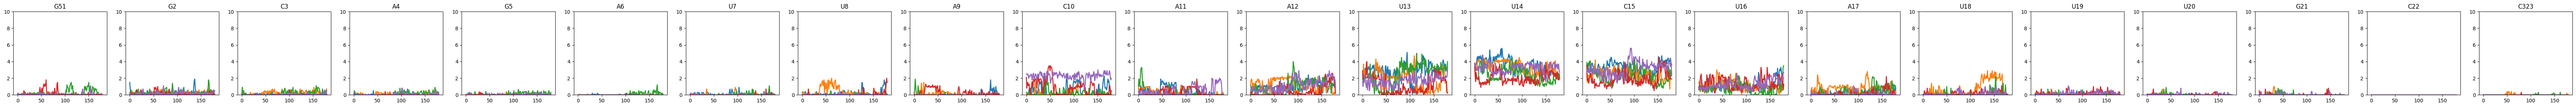

In [2]:
YMAX = 10

fig, ax = plt.subplots(1,23)
fig.set_size_inches(92, 3)

for residue_index_rna in range(0, 23):
    atom_indices_rna_residue = gleap_target.topology.select(f"resid {residue_index_rna}")
    atom_index_rna_residue_min = min(atom_indices_rna_residue)
    atom_index_rna_residue_max = max(atom_indices_rna_residue)

    for trial in range(len(cmd_interactions)):
        ax[residue_index_rna].plot(cmd_interactions[trial, :, atom_index_rna_residue_min:atom_index_rna_residue_max+1, :].sum(axis=(0, 1)).reshape(-1, 10).mean(axis=1), linewidth=2)

    ax[residue_index_rna].set_title(gleap_target.topology.residue(residue_index_rna))
    ax[residue_index_rna].set_ylim(0, YMAX)

C10-O2-ARG125-HE 0.0137524557956778 0.3059643687064291
A12-H61-LEU72-O 0.4911591355599214 0.0
U13-H3-THR74-OG1 0.6227897838899804 0.08288148721920992
U13-O2-THR74-H 0.6404715127701375 0.08597986057319908
U14-O2-THR118-H 0.9960707269155207 0.9876065065840434
U14-O2'-THR118-HG1 0.555992141453831 0.5143299767621998
U14-HO2'-THR118-O 0.7328094302554028 0.7079783113865221
C15-OP2-ARG120-H 0.6836935166994106 0.6219984508133231
C15-OP2-ALA121-H 0.38703339882121807 0.2509682416731216
C15-H42-ALA117-O 0.40078585461689586 0.39504260263361735
C15-O2-THR34-HG1 0.34970530451866405 0.2579395817195972
U16-OP2-ASN71-HD21 0.48919449901768175 0.2974438419829589


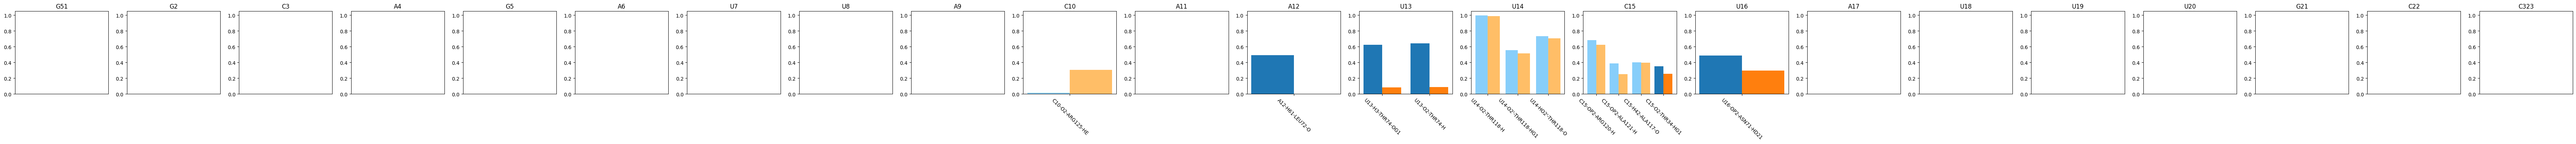

In [3]:
def make_label_protein(atom):
    return f"{atom.residue.name}{atom.residue.index}-{atom.name}"
    return f"{atom.residue.name}{atom.residue.index+252}-{atom.name}"


atom_indices_protein_rgion = {
    "rrm": list(gleap_target.topology.select("resid  24 to 116")),
    "rgg": list(gleap_target.topology.select("resid 117 to 125")),
}

colors = [
    {
        "rrm": "tab:blue",
        "rgg": "lightskyblue",
    },
    {
        "rrm": "tab:orange",
        "rgg": "#FFBE67",
    },
]

FRACTION_THRESHOLD = 0.3

fig, ax = plt.subplots(1, 23)
fig.set_size_inches(92, 3)

# cmd_interactions_transpose_concat = np.concatenate(cmd_interactions.transpose(0, 3, 1, 2))
cmd_interactions_transpose_concat = np.concatenate(cmd_interactions[:, :, :, ::5].transpose(0, 3, 1, 2))

metastabled_trajs_concat = pickle.load(open(f"./pickle-cache/pca_tetranucl/metastabled_trajs_concat_2.pickle", "rb"))[::50]
for residue_index_rna in range(0, 23):
    atom_idices_rna_residue = gleap_target.topology.select(f"resid {residue_index_rna}")
    atom_index_rna_residue_min = min(atom_idices_rna_residue)
    atom_index_rna_residue_max = max(atom_idices_rna_residue)

    i_bar = 0
    xticks = []
    for atom_index_rna_residue in range(atom_index_rna_residue_min, atom_index_rna_residue_max+1):
        for atom_index_protein in atom_indices_protein:
            fraction_0 = cmd_interactions_transpose_concat[metastabled_trajs_concat==0, atom_index_protein-atom_index_protein_min, atom_index_rna_residue].mean()
            fraction_1 = cmd_interactions_transpose_concat[metastabled_trajs_concat==1, atom_index_protein-atom_index_protein_min, atom_index_rna_residue].mean()

            region = "rrm"
            if atom_index_protein in atom_indices_protein_rgion["rgg"]:
                region = "rgg"
            if fraction_0 > FRACTION_THRESHOLD or fraction_1 > FRACTION_THRESHOLD:
                ax[residue_index_rna].bar(i_bar-0.2, fraction_0, width=0.4, color=colors[0][region])
                ax[residue_index_rna].bar(i_bar+0.2, fraction_1, width=0.4, color=colors[1][region])
                i_bar += 1
                xticks.append(f"{gleap_target.topology.atom(atom_index_rna_residue)}-{make_label_protein(gleap_target.topology.atom(atom_index_protein))}")
                print(f"{gleap_target.topology.atom(atom_index_rna_residue)}-{make_label_protein(gleap_target.topology.atom(atom_index_protein))}", fraction_0, fraction_1)

    ax[residue_index_rna].set_title(gleap_target.topology.residue(residue_index_rna))
    ax[residue_index_rna].set_ylim(0, 1.05)
    ax[residue_index_rna].set_xticks(range(len(xticks)), xticks, rotation=-45)

del cmd_interactions_transpose_concat

C10-O2-ARG125-HE 0.0137524557956778 0.3059643687064291
C10-O2-ARG125-HH11 0.009823182711198428 0.17428350116189
C10-O2'-NME126-H 0.0 0.1758326878388846
A11-O3'-ARG125-HH11 0.10805500982318271 0.0
A12-OP1-ARG125-HE 0.11591355599214145 0.000774593338497289
A12-OP1-NME126-H 0.13359528487229863 0.0077459333849728895
A12-H61-LEU72-O 0.4911591355599214 0.0
A12-H62-THR74-OG1 0.2220039292730845 0.0
U13-OP1-THR74-H 0.0 0.16266460108443068
U13-OP1-ARG76-HH21 0.18664047151277013 0.006971340046475601
U13-OP2-ARG76-HH12 0.13948919449901767 0.026336173508907823
U13-OP2-ARG76-HH22 0.2082514734774067 0.03408210689388071
U13-O4-ARG76-H 0.005893909626719057 0.19984508133230056
U13-H3-THR74-OG1 0.6227897838899804 0.08288148721920992
U13-H3-THR74-O 0.05697445972495088 0.2308288148721921
U13-O2-THR74-H 0.6404715127701375 0.08597986057319908
U13-O2-ARG76-H 0.25736738703339884 0.056545313710302095
U13-O2'-LYS82-HZ1 0.10805500982318271 0.037955073586367155
U13-O2'-LYS82-HZ2 0.137524557956778 0.033307513555383

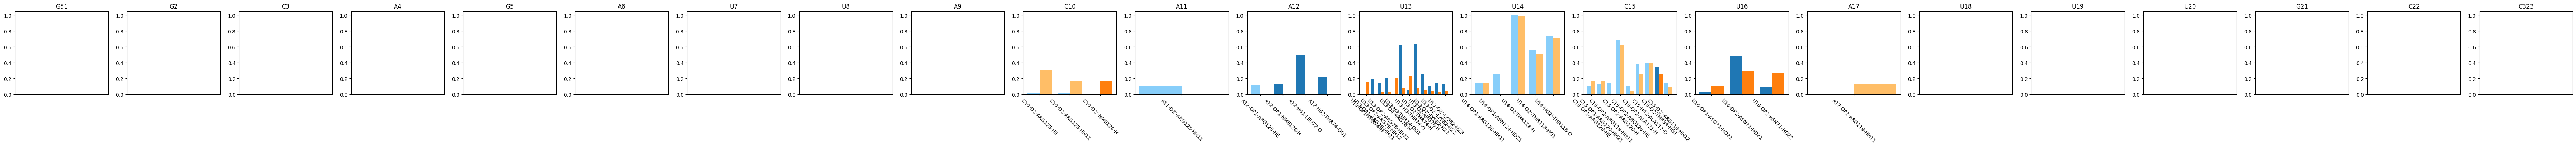

In [4]:
def make_label_protein(atom):
    return f"{atom.residue.name}{atom.residue.index}-{atom.name}"
    return f"{atom.residue.name}{atom.residue.index+252}-{atom.name}"


atom_indices_protein_rgion = {
    "rrm": list(gleap_target.topology.select("resid  24 to 116")),
    "rgg": list(gleap_target.topology.select("resid 117 to 125")),
}

colors = [
    {
        "rrm": "tab:blue",
        "rgg": "lightskyblue",
    },
    {
        "rrm": "tab:orange",
        "rgg": "#FFBE67",
    },
]

FRACTION_THRESHOLD = 0.1

fig, ax = plt.subplots(1, 23)
fig.set_size_inches(92, 3)

# cmd_interactions_transpose_concat = np.concatenate(cmd_interactions.transpose(0, 3, 1, 2))
cmd_interactions_transpose_concat = np.concatenate(cmd_interactions[:, :, :, ::5].transpose(0, 3, 1, 2))

metastabled_trajs_concat = pickle.load(open(f"./pickle-cache/pca_tetranucl/metastabled_trajs_concat_2.pickle", "rb"))[::50]
for residue_index_rna in range(0, 23):
    atom_idices_rna_residue = gleap_target.topology.select(f"resid {residue_index_rna}")
    atom_index_rna_residue_min = min(atom_idices_rna_residue)
    atom_index_rna_residue_max = max(atom_idices_rna_residue)

    i_bar = 0
    xticks = []
    for atom_index_rna_residue in range(atom_index_rna_residue_min, atom_index_rna_residue_max+1):
        for atom_index_protein in atom_indices_protein:
            fraction_0 = cmd_interactions_transpose_concat[metastabled_trajs_concat==0, atom_index_protein-atom_index_protein_min, atom_index_rna_residue].mean()
            fraction_1 = cmd_interactions_transpose_concat[metastabled_trajs_concat==1, atom_index_protein-atom_index_protein_min, atom_index_rna_residue].mean()

            region = "rrm"
            if atom_index_protein in atom_indices_protein_rgion["rgg"]:
                region = "rgg"
            if fraction_0 > FRACTION_THRESHOLD or fraction_1 > FRACTION_THRESHOLD:
                ax[residue_index_rna].bar(i_bar-0.2, fraction_0, width=0.4, color=colors[0][region])
                ax[residue_index_rna].bar(i_bar+0.2, fraction_1, width=0.4, color=colors[1][region])
                i_bar += 1
                xticks.append(f"{gleap_target.topology.atom(atom_index_rna_residue)}-{make_label_protein(gleap_target.topology.atom(atom_index_protein))}")
                print(f"{gleap_target.topology.atom(atom_index_rna_residue)}-{make_label_protein(gleap_target.topology.atom(atom_index_protein))}", fraction_0, fraction_1)

    ax[residue_index_rna].set_title(gleap_target.topology.residue(residue_index_rna))
    ax[residue_index_rna].set_ylim(0, 1.05)
    ax[residue_index_rna].set_xticks(range(len(xticks)), xticks, rotation=-45)

del cmd_interactions_transpose_concat

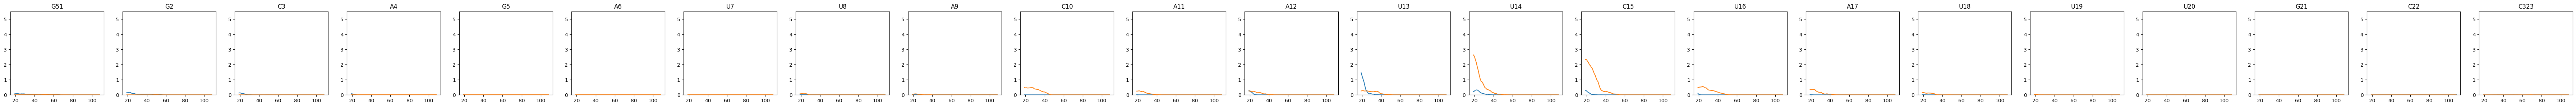

In [5]:
fig, ax = plt.subplots(1, 23)
fig.set_size_inches(92, 3)

pacs_interactions_trial_mean = pacs_interactions.mean(axis=0)

for residue_index_rna in range(0, 23):
    atom_idices_rna_residue = gleap_target.topology.select(f"resid {residue_index_rna}")

    pacs_interactions_trial_mean_rna_sum = pacs_interactions_trial_mean[:, atom_idices_rna_residue].sum(axis=1)

    ax[residue_index_rna].plot(pacs_interactions_trial_mean_rna_sum[atom_indices_protein_rgion["rrm"]-atom_index_protein_min].sum(axis=0))
    ax[residue_index_rna].plot(pacs_interactions_trial_mean_rna_sum[atom_indices_protein_rgion["rgg"]-atom_index_protein_min].sum(axis=0))

    ax[residue_index_rna].set_title(gleap_target.topology.residue(residue_index_rna))
    ax[residue_index_rna].set_ylim(0, 5.5)

In [6]:
fig, ax = plt.subplots(len(pacs_interactions), 23)
fig.set_size_inches(92, 3*len(pacs_interactions))

for trial in range(len(pacs_interactions)):
    for residue_index_rna in range(0, 23):
        atom_idices_rna_residue = gleap_target.topology.select(f"resid {residue_index_rna}")

        pacs_interactions_rna_sum = pacs_interactions[trial, :, atom_idices_rna_residue].sum(axis=0)

        ax[trial, residue_index_rna].plot(pacs_interactions_rna_sum[atom_indices_protein_rgion["rrm"]-atom_index_protein_min].sum(axis=0))
        ax[trial, residue_index_rna].plot(pacs_interactions_rna_sum[atom_indices_protein_rgion["rgg"]-atom_index_protein_min].sum(axis=0))

        ax[trial, residue_index_rna].set_title(f"{trial}-{gleap_target.topology.residue(residue_index_rna)}")
        ax[trial, residue_index_rna].set_ylim(0, 5.5)

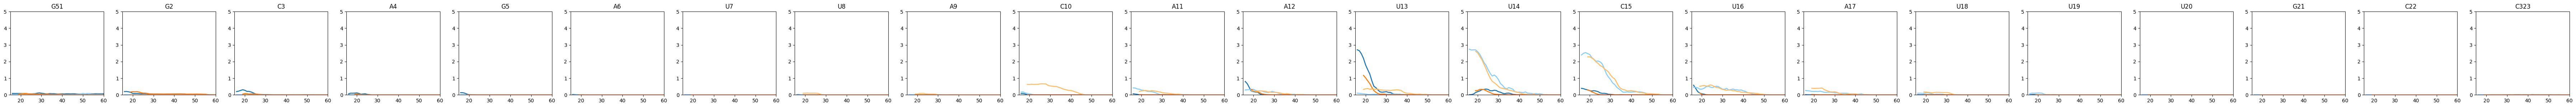

In [7]:
trial_groups_initial = [
    [1, 2, 3, 4, 5, 6, 7, 9, 24, 25, 26, 27, 28, 29],
    [],
]
trial_groups_initial[1] = [trial for trial in range(50) if not trial in trial_groups_initial[0]]


fig, ax = plt.subplots(1, 23)
fig.set_size_inches(92, 3)

for i_trial_group, trial_group_trials in enumerate(trial_groups_initial):
    pacs_interactions_trial_sum = np.zeros((len(atom_indices_protein), len(atom_indices_rna), 120))
    for trial in trial_group_trials:
        pacs_interactions_trial_sum += pacs_interactions[trial]
    pacs_interactions_trial_mean = pacs_interactions_trial_sum / len(trial_group_trials)
    
    for residue_index_rna in range(0, 23):
        atom_idices_rna_residue = gleap_target.topology.select(f"resid {residue_index_rna}")
    
        pacs_interactions_trial_mean_rna_sum = pacs_interactions_trial_mean[:, atom_idices_rna_residue].sum(axis=1)
    
        ax[residue_index_rna].plot(pacs_interactions_trial_mean_rna_sum[atom_indices_protein_rgion["rrm"]-atom_index_protein_min].sum(axis=0), c=colors[i_trial_group]["rrm"], linestyle="-", linewidth=2)
        ax[residue_index_rna].plot(pacs_interactions_trial_mean_rna_sum[atom_indices_protein_rgion["rgg"]-atom_index_protein_min].sum(axis=0), c=colors[i_trial_group]["rgg"], linestyle="-", linewidth=2)
    
        ax[residue_index_rna].set_title(gleap_target.topology.residue(residue_index_rna))
        ax[residue_index_rna].set_xlim(15, 60)
        ax[residue_index_rna].set_ylim(0, 5)

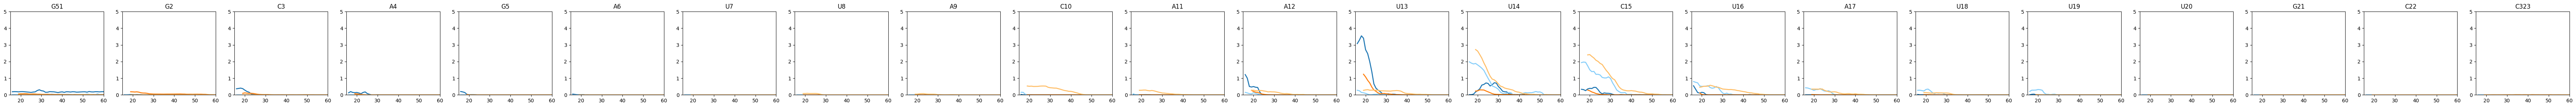

In [8]:
trial_groups_initial = [
    [7, 25, 26, 28, 29],
    [],
]
trial_groups_initial[1] = [trial for trial in range(50) if not trial in trial_groups_initial[0]]


fig, ax = plt.subplots(1, 23)
fig.set_size_inches(92, 3)

for i_trial_group, trial_group_trials in enumerate(trial_groups_initial):
    pacs_interactions_trial_sum = np.zeros((len(atom_indices_protein), len(atom_indices_rna), 120))
    for trial in trial_group_trials:
        pacs_interactions_trial_sum += pacs_interactions[trial]
    pacs_interactions_trial_mean = pacs_interactions_trial_sum / len(trial_group_trials)
    
    for residue_index_rna in range(0, 23):
        atom_idices_rna_residue = gleap_target.topology.select(f"resid {residue_index_rna}")
    
        pacs_interactions_trial_mean_rna_sum = pacs_interactions_trial_mean[:, atom_idices_rna_residue].sum(axis=1)
    
        ax[residue_index_rna].plot(pacs_interactions_trial_mean_rna_sum[atom_indices_protein_rgion["rrm"]-atom_index_protein_min].sum(axis=0), c=colors[i_trial_group]["rrm"], linestyle="-", linewidth=2)
        ax[residue_index_rna].plot(pacs_interactions_trial_mean_rna_sum[atom_indices_protein_rgion["rgg"]-atom_index_protein_min].sum(axis=0), c=colors[i_trial_group]["rgg"], linestyle="-", linewidth=2)
    
        ax[residue_index_rna].set_title(gleap_target.topology.residue(residue_index_rna))
        ax[residue_index_rna].set_xlim(15, 60)
        ax[residue_index_rna].set_ylim(0, 5)